In [1]:
import os
import cv2
import pyewts
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from glob import glob
from natsort import natsorted
from Utils import get_lines_from_page, create_dir, binarize_line, pad_image2, prepare_ocr_image2
from Utils import build_xml_document


from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference, KerasInference
from evaluate import load

converter = pyewts.pyewts()

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [131]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4, axis="off"):
    plt.figure(figsize=(18, 9))
    plt.axis(axis)
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)

def pad_line(image: np.array, pad_width: int = 20) -> np.array:
    pad_slice = np.ones(shape=(image.shape[0], pad_width, 3), dtype=np.uint8)
    pad_slice *=255
    padded_line = np.hstack([pad_slice, image, pad_slice])

    return padded_line

In [3]:
layout_config = "Models/LayoutModels/Classic/LA_v2_2024-1-22_6-36/model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [4]:
models_path = "Models/OCRModels"
#dataset = "DergeTenjur"
#chkpt_path = "2024_1_30_9_38"


dataset = "MixedWoodBlock_v1"
chkpt_path = "2024_2_1_22_12"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"


#dataset = "LhasaKanjurEaster"
#chkpt_path = "2024_1_29_11_45"
#ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"

#dataset = "SynthUchen"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

In [139]:
#data_root = "D:/Datasets/Tibetan/Glomanthang/Volumes/W2KG229028-v25"
data_root = "C:/Users/Eric/Downloads/W3CN636"
#data_root = "E:/BDRC-Bucket/W2PD16805/images/W2PD16805-I4PD2814"
#image_path = data_root
images = natsorted(glob(f"{data_root}/*.jpg"))

print(f"Images: {len(images)}")

Images: 686


I3CN6390006


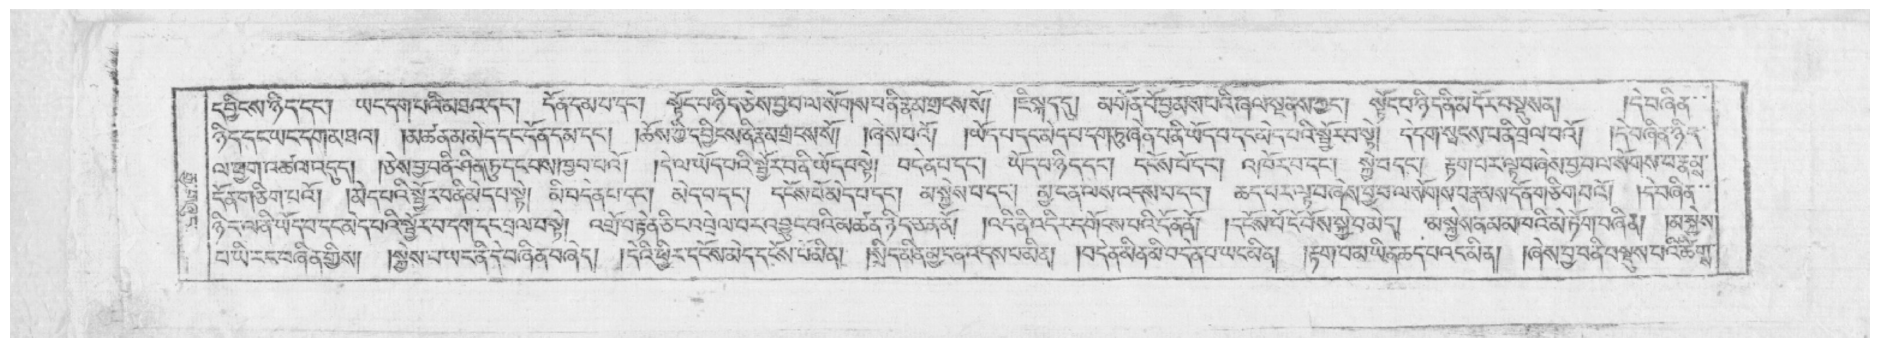

In [135]:
idx = 3
test_image_name = os.path.basename(images[idx]).split(".")[0]
print(test_image_name)
test_image = cv2.imread(images[idx])

show_image(test_image)

In [136]:
prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(test_image, 0)
line_images = [binarize_line(x, adaptive=True, block_size=15) for x in line_images]
line_images = [pad_line(x) for x in line_images]

np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in line_images]
np_img_batch = np.array(np_img_batch, np.float32)

predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)



dbyings nyid dang /yang dag pa'i mtha' dang /don dam pa dang /stong pa nyid ces bya ba la sogs pa ni rnam grangs so//ji skad du/mgon po byams pa'i zhal sngams kyang /stong pa nyid ni mdor bsdus na//de bzhin 
nyid dang yang dag mtha'//mtshan ma med dang don dam dang //chos kyi dbyings ni rnam grangs so//zhes pa'o//yod pa dang med pa dag tu zhen pa ni yod pa dang med pa'i sbyor ba ste/de dag sungs pa ri brel ba'o//de bzhin nyid 
la phyag 'tshal 'dud//ces bya ba ni shig tu dang bas khyab pa'o//de la yod pa'i sbyor ba ni yod pa ste/bden pa dang /yod pa nyid dang /dngos po dang /'khor ba dang /skye ba dang /rtag par lta ba zhes bya ba la sogs pa rnams 
do ta gcig pa'o//med pa'i sbyor ba ni med pa ste/mi bden pa dang /med pa dang /dngos po med pa dang /ma skyes pa dang /mya ngan las 'das pa dang /chad par lta ba zhes bya ba la sogs pa rlabs dod gcig pa'o//de bzhin 
nyid la ni yod pa dang med pa'i sbyor ba dag dang bral ba ste/'gro brten cing 'brel par 'byung ba'i mtshan nyid can no//'di ni '

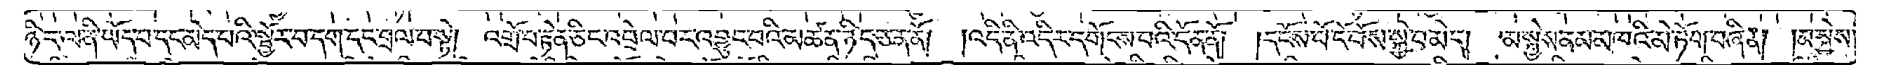

In [137]:
show_image(line_images[-2])

In [29]:
output_dir = os.path.join(data_root, "page")
create_dir(output_dir)
xml_out = os.path.join(output_dir,"page")
create_dir(xml_out)

In [30]:
xml_results = build_xml_document(rotated_image, test_image_name, bbox, sorted_contours, predicted_text)

with open(f"{xml_out}/{test_image_name}.xml", "w", encoding="utf-8") as f:
            f.write(xml_results)

In [140]:
ocr_predictions = {}

for idx, image_path in tqdm(enumerate(images), total=len(images)):
    image_name = os.path.basename(images[idx]).split(".")[0]
    image = cv2.imread(images[idx])
    prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(image, 0)
    line_images = [binarize_line(x, adaptive=True, block_size=15) for x in line_images]
    line_images = [pad_line(x) for x in line_images]

    if len(line_images) > 0:
        #line_images = [tweak_image(x) for x in line_images]
        np_img_batch = [
                    prepare_ocr_image2(
                        x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
                    ) for x in line_images]
        np_img_batch = np.array(np_img_batch)

        predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
        predicted_text = [converter.toUnicode(x) for x in predicted_text]

        ocr_predictions[image_name] = predicted_text
        """
        xml_results = build_xml_document(rotated_image, image_name, bbox, sorted_contours, predicted_text)

        with open(f"{xml_out}/{image_name}.xml", "w", encoding="utf-8") as f:
            f.write(xml_results)

        """

out_file = f"{data_root}/etext2.txt"

with open(out_file, "w", encoding="utf-8") as f:
    for k, v in ocr_predictions.items():
        f.write(f"<page id='{k}'>\n")
        for line in v:
            f.write(f"<line>{line}</line>\n")
        f.write("</page>\n")

100%|██████████| 686/686 [07:05<00:00,  1.61it/s]


In [82]:
ocr_predictions = {}

for idx, image_path in tqdm(enumerate(images), total=len(images)):
    image_name = os.path.basename(images[idx]).split(".")[0]
    image = cv2.imread(images[idx])
    prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(image, 0)


    if len(line_images) > 0:
        #line_images = [tweak_image(x) for x in line_images]
        np_img_batch = [
                    prepare_ocr_image2(
                        x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
                    ) for x in line_images]
        np_img_batch = np.array(np_img_batch)

        predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
        predicted_text = [x for x in predicted_text if x != ""]
        predicted_text = [converter.toUnicode(x) for x in predicted_text]

        ocr_predictions[image_name] = predicted_text


out_file = f"{data_root}/etext.txt"

with open(out_file, "w", encoding="utf-8") as f:
    for k, v in ocr_predictions.items():
        f.write(f"<page id='{k}'>\n")
        for line in v:
            f.write(f"<line>{line}</line>\n")
        f.write("</page>\n")

100%|██████████| 968/968 [11:04<00:00,  1.46it/s]


In [84]:
out_file = f"{data_root}/etext.txt"

with open(out_file, "w", encoding="utf-8") as f:
    for k, v in ocr_predictions.items():
        f.write(f"<page id='{k}'>\n")
        for line in v:
            f.write(f"<line>{line}</line>\n")
        f.write("</page>\n")

#### Pipeline using LayoutModel

In [21]:
from DataClasses import LineData
from Utils import calculate_dilate_iterations

In [23]:
from Utils import rotate_from_angle, get_line_treshold, get_line_bbox_centers, group_bbox_centers, get_random_color, get_line_images_from_line_data

In [24]:
layout_config = "Models/LayoutModels/Classic/LA_v2_2024-1-22_6-36/model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

I3CN6400006
24.0


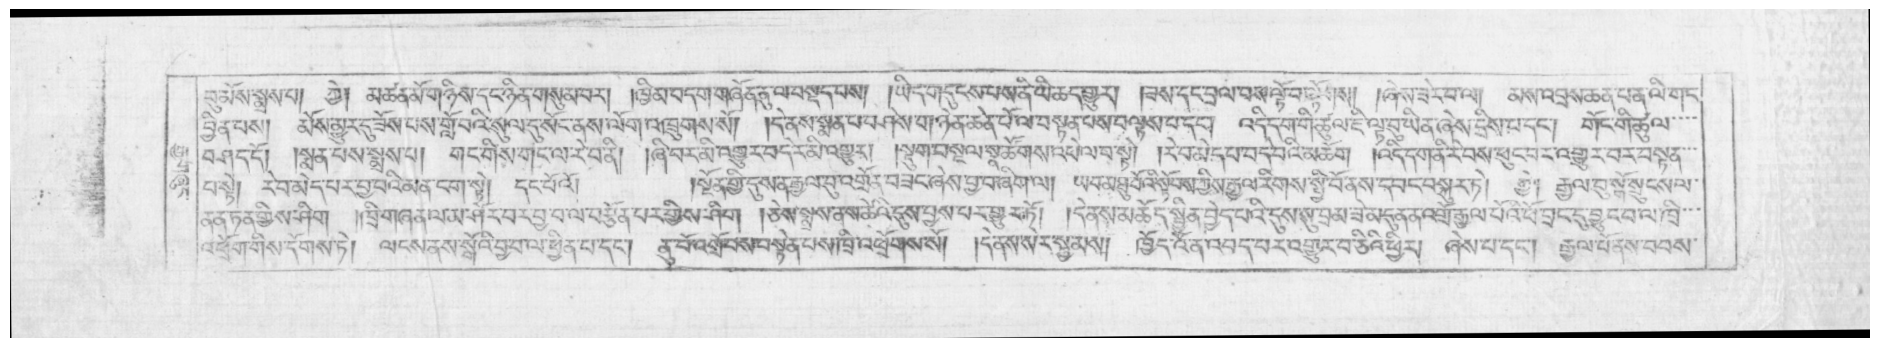

In [25]:
idx = 3
image_name = os.path.basename(images[idx]).split(".")[0]
image = cv2.imread(images[idx])
print(image_name)
layout_data, preview_img = layout_inference.predict(image)
r_img = rotate_from_angle(image, layout_data.rotation)

line_threshold = get_line_treshold(layout_data.predictions["lines"])

print(line_threshold)
bbox_centers = get_line_bbox_centers(layout_data)
sorted_bbox_centers = group_bbox_centers(bbox_centers, line_threshold=line_threshold)
show_image(r_img)

6


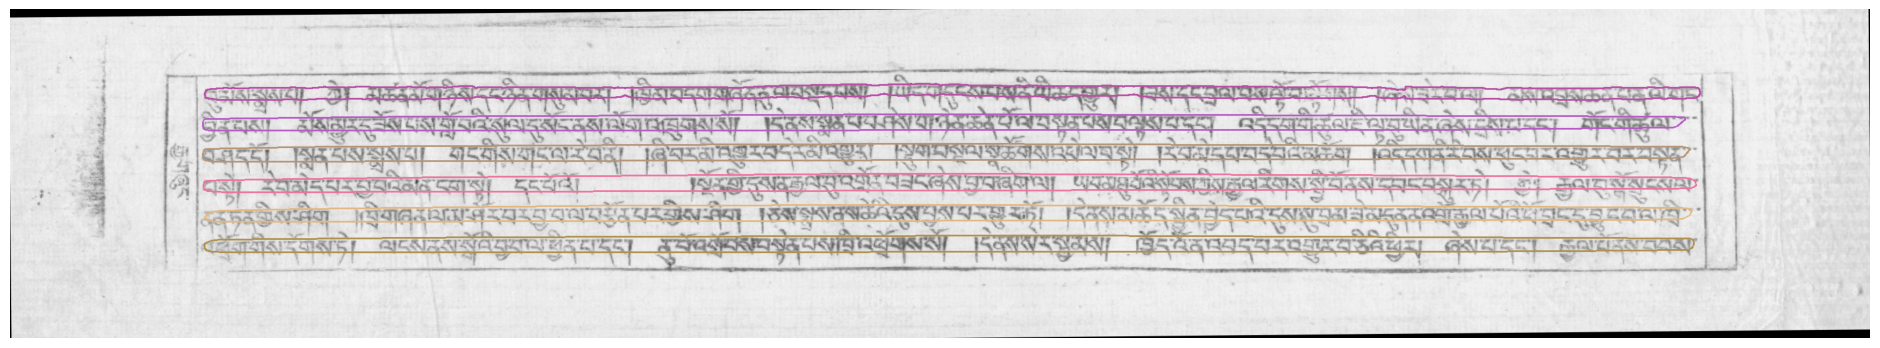

In [26]:
sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=True)

prev_img = r_img.copy()
color = get_random_color()
print(len(layout_data.lines))

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [48]:
from Utils import get_line_image_from_bbox

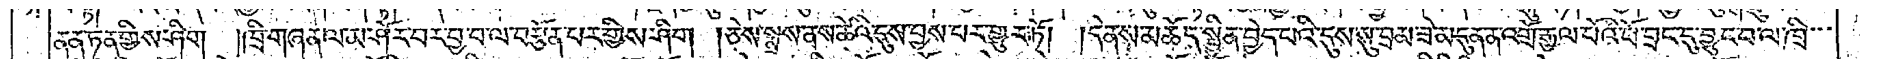

In [124]:
bbox_lines = [get_line_image_from_bbox(r_img, line, x_offset=70) for line in sorted_layout_data.lines]
bbox_lines = [binarize_line(x, adaptive=True, block_size=15, c=7) for x in bbox_lines]

show_image(bbox_lines[-2])

In [125]:
bbox_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in bbox_lines]
bbox_img_batch = np.array(bbox_img_batch, np.float32)

predicted_text, raw = ocr_inference.run(bbox_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)


nyis pagsspangyis p dag pntu nala bsnad pas//yid gdangs pas de'i cu gyur//phas pang bam pas ap par bug papagi gang 
gas pas rgapsgzugs so//de nas sman pa bshes panyis chen po la bstan pas bltas pa dang /'di dag gi as jis pa'i aiap i
bsmyan pas smras pa/gang gis gang la re ba'i//zyi bar mi 'gyur ba der mi 'gyur//sdug bsngal sna tshogs 'phel ba ste//re ba med pa bde ba'i mchib /'di dag ni ribs phung bar 'gyur bar bstan 
pal/deba med par bya ba'i man ngag ste/dang po'o//sngon gyi dus na rgyal bu 'gror bzang zhes bya ba zhig la/yab mthu bo'i stobs kyis gyal rigs spyi bo nas dbang bskur te/kye/rgyal bu spgo spangs la 
kyes shig/mri gzag pa la shing par bya ba la brtsan par gyis shig /ces smras nas che'i dus byas par gyur to//de nas mchod sbyin byed pa'i dus su bram ze mdugga'gri rgyal po 'as byung du
g gis rams te/sangs rgyas su'i byum la byin pa dang ms pas bsten pas khre 'phrogs so//de nas ser snams/khyad din 'bad par bgyid pa ci'i phyir/shes pa dang /rgyal sogs pa bas


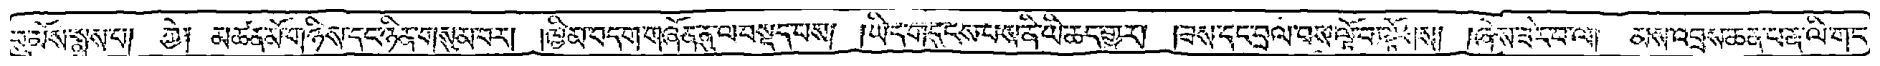

In [117]:
layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=36, calculate_iterations=True, binarize=False)
layout_line_images = [binarize_line(x, adaptive=True, block_size=15) for x in layout_line_images]
show_image(layout_line_images[0])

In [102]:
prediction, rotated_image, linedetect_images, sorted_contours, bbox, peaks = line_inference.predict(image, 0)
linedetect_images = [binarize_line(x, adaptive=True, block_size=15) for x in linedetect_images]

np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in linedetect_images]
np_img_batch = np.array(np_img_batch, np.float32)

predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)


bu mos smras pa/kye/mtshan mo gnyis dang nyin gsum par//khyim bdag gzhon nu la bstad pas//yid gdungs pas ni yi chad gyur//zas dang bral bas lto ba ltogs//zhes zer ba la/mas 'bras chan pa na li gang 
bin pas/mos myur du zos pas sgo ba'i sal du song nas log 'khrugs so//de nas sman pa bshes gnyen chen po la bstan pas bltas pa dang /'di dag gi tshul ji lta bu yin zhes dris pa dang /gong gi tshul 
bshad do //sman pas smras pa/gang gis gang la re ba ni//zhi bar mi 'gyur ba der mi 'gyur//sdug bsngal sna tshogs 'phel ba ste//re ba med pa bde ba'i mchog /'di dag ni ribs phung bar 'gyur bar bstan 
pa ste/ri ba med par bya ba'i man ngag ste/dang po'o//sngon gyi dus na rgyal bu 'gror bzang zhes bya ba zhig la/yab mtho bo'i stobs kyis blal rigs spyi bo nas dbang bskur te/rgyal bu sngo spangs la 
ngan nyin gyis shig /khri gzhan la ma shor bar bya ba la brtson par gyis shig /ces smras nas tshe'i dus byas par gyur to//de nas mchod sbyin byed pa'i dus su bram ze mdun na 'gro rgyal po'i pho brang du byu

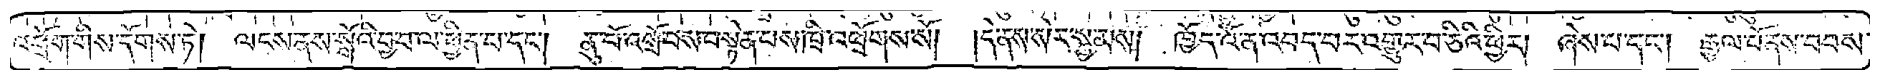

In [101]:
show_image(linedetect_images[-1])

(84, 2637, 3)
(84, 16, 3)
(84, 2669, 3)


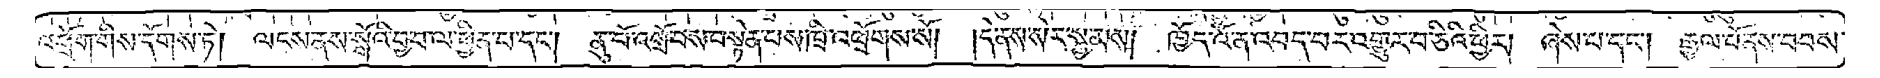

In [114]:
line_test = linedetect_images[-1]
print(line_test.shape)
pad_slice = np.ones(shape=(84, 16, 3), dtype=np.uint8)
pad_slice *=255
print(pad_slice.shape)
padded_line = np.hstack([pad_slice, line_test, pad_slice])
print(padded_line.shape)

show_image(padded_line)

In [116]:
img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in [padded_line]]
img_batch = np.array(img_batch, np.float32)

predicted_text, raw = ocr_inference.run(img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)


pphrog gis dogs te/langs nas spo'i bya ba la sbyin pa dang /nu bo 'gro bas bsten pas khri 'phrogs so//de nas ser snams/khyod pona 'bad par 'gyur ba ci'i phyir/shes pa dang /rgyal po ngas babs 


#/slob dpon klu sgrub kyis mdzad pa'i doditshigs su bcad pa phyed dang lha'i 'gyel pa bzhugs so///
slob dpor sma sgrub snying po'i zhel snga nas/re ba'i as gyisdsudogap rgyal byabmes nyas//btam ppain
pa sdag rgyarpan b'mar kyang byed mi byer gzugs//sum sms//noms gam pmas pal pa 'am
pas nga rgyal chos kyi wa//sbom la der 'dzin ya shu ha/spyod pas ngargyal dzin pa//dka' bas rlom sems bzang skong bu//dbang gis 


In [143]:
#data_root = "D:/Datasets/Tibetan/Glomanthang/Volumes/W2KG229028-v25"
data_root = "C:/Users/Eric/Downloads/W3CN636"
#data_root = "E:/BDRC-Bucket/W2PD16805/images/W2PD16805-I4PD2814"
#image_path = data_root
images = natsorted(glob(f"{data_root}/*.jpg"))

print(f"Images: {len(images)}")

Images: 686


In [144]:
ocr_predictions = {}

for idx, image_path in tqdm(enumerate(images), total=len(images)):
    image_name = os.path.basename(image_path).split(".")[0]
    image = cv2.imread(image_path)

    layout_data, preview_img = layout_inference.predict(image)
    r_img = rotate_from_angle(image, layout_data.rotation)

    if layout_data.predictions["lines"] is not None:
        line_threshold = get_line_treshold(layout_data.predictions["lines"])
        bbox_centers = get_line_bbox_centers(layout_data)
        sorted_bbox_centers = group_bbox_centers(bbox_centers, line_threshold=line_threshold)
        sorted_layout_data = layout_inference.sort_lines(layout_data)

        line_images = [get_line_image_from_bbox(r_img, line, x_offset=60) for line in sorted_layout_data.lines]


        if len(line_images) > 0:
            img_batch = [
                        prepare_ocr_image2(
                            x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
                        ) for x in line_images]
            img_batch = np.array(img_batch)

            predicted_text, raw = ocr_inference.run(img_batch, replace_tsheg=" ")
            predicted_text = [x for x in predicted_text if x != ""]
            predicted_text = [converter.toUnicode(x) for x in predicted_text]

            ocr_predictions[image_name] = predicted_text


out_file = f"{data_root}/etext.txt"

with open(out_file, "w", encoding="utf-8") as f:
    for k, v in ocr_predictions.items():
        f.write(f"<page id='{k}'>\n")
        for line in v:
            f.write(f"<line>{line}</line>\n")
        f.write("</page>\n")

100%|██████████| 686/686 [08:06<00:00,  1.41it/s]
